# Part G — Diagonalization

**Final Project: Philippine Peso Depreciation Early-Warning Model: Predicting the Next-Month PHP/USD Exchange Rate Using Linear Regression and PCA**

Once a matrix is diagonalized, keeping only the most important directions becomes a simple, principled way to reduce dimensionality.

---
**Student name:** Alfajaro, Ghan Vincent | Arile, Charles Jullianne | Asuar, Jhoe Maven | Mondragon, Leneth | Ulitin, Justin |   **Date:** November 20, 2026

---

**What to do:** Diagonalize your matrix from Part F (C = VΛV⁻¹, or C = VΛVᵀ if symmetric) and use it to reduce dimensionality.

In [1]:
# Run this first: recall variables saved from the previous parts' notebooks.
# If the %store is empty (fresh runtime), rebuild everything from the CSV that Part A saved
# (peso_usd_part_a_dataset.csv) using exactly the same steps as Parts D and F.
%store -r C eigvals eigvecs X_train X_test y_train y_test

import numpy as np
import pandas as pd

try:
    _ = (C, eigvals, eigvecs, X_train, X_test, y_train, y_test)
    print("Loaded C, eigvals, eigvecs, X_train, X_test, y_train, y_test from %store.")
except NameError:
    print("Store is empty: rebuilding from peso_usd_part_a_dataset.csv ...")
    df = pd.read_csv("peso_usd_part_a_dataset.csv", index_col="FeatureMonth")
    feats = ["CurrentRate", "Trailing3MonthAverage", "YearOverYearChange"]
    X_all, y_all = df[feats].to_numpy(float), df["NextMonthRate"].to_numpy(float)

    # Part D: chronological 80/20 split, mu and sigma from the TRAINING rows only
    train_size = int(0.8 * X_all.shape[0])
    mu = X_all[:train_size].mean(axis=0)
    sigma = X_all[:train_size].std(axis=0, ddof=0)
    X_std = (X_all - mu) / sigma
    X_train, X_test = X_std[:train_size], X_std[train_size:]
    y_train, y_test = y_all[:train_size], y_all[train_size:]

    # Part F: covariance matrix of the standardized training features, then eigh
    C = np.cov((X_train - X_train.mean(axis=0)) / X_train.std(axis=0, ddof=1), rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(C)
    idx = np.argsort(eigvals)[::-1]
    eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]
    print("Rebuilt X_train", X_train.shape, "and X_test", X_test.shape)

Loaded C, eigvals, eigvecs, X_train, X_test, y_train, y_test from %store.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

In [3]:
C = np.asarray(C, dtype=float)
eigvals = np.asarray(eigvals, dtype=float).ravel()
eigvecs = np.asarray(eigvecs, dtype=float)
X_train = np.asarray(X_train, dtype=float)
X_test = np.asarray(X_test, dtype=float)
y_train = np.asarray(y_train, dtype=float).ravel()

print("Covariance matrix:", C.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Covariance matrix: (3, 3)
Training features: (342, 3)
Testing features: (86, 3)


In [4]:
order = np.argsort(eigvals)[::-1]
eigvals_sorted = eigvals[order]
V = eigvecs[:, order]
Lambda = np.diag(eigvals_sorted)

print("Sorted eigenvalues:")
print(eigvals_sorted)
print("\nV = eigenvectors:")
print(V)
print("\nLambda = diagonal eigenvalue matrix:")
print(Lambda)
print("\nDimensions of V:", V.shape)
print("Dimensions of Lambda:", Lambda.shape)

print("\nV.T @ V is identity:", np.allclose(V.T @ V, np.eye(V.shape[1])))
C_reconstructed = V @ Lambda @ V.T
print("V @ Lambda @ V.T reconstructs C:", np.allclose(C, C_reconstructed))
print("Maximum reconstruction difference:", np.max(np.abs(C - C_reconstructed)))


Sorted eigenvalues:
[2.0141 0.9841 0.0017]

V = eigenvectors:
[[-0.7024 -0.0746 -0.7079]
 [-0.7006 -0.1031  0.706 ]
 [-0.1256  0.9919  0.0201]]

Lambda = diagonal eigenvalue matrix:
[[2.0141 0.     0.    ]
 [0.     0.9841 0.    ]
 [0.     0.     0.0017]]

Dimensions of V: (3, 3)
Dimensions of Lambda: (3, 3)

V.T @ V is identity: True
V @ Lambda @ V.T reconstructs C: True
Maximum reconstruction difference: 1.5543122344752192e-15


In [5]:
# Extra verification of the diagonalization (three independent checks)

# (1) Diagonalizing from the other side: V^T C V should give back Lambda.
Lambda_check = V.T @ C @ V
print("V^T C V =")
print(Lambda_check)
print("V^T C V equals Lambda:", np.allclose(Lambda_check, Lambda))

# (2) Spectral form: C = sum_i lambda_i * v_i v_i^T (a sum of three rank-1 matrices)
C_spectral = sum(eigvals_sorted[i] * np.outer(V[:, i], V[:, i]) for i in range(V.shape[1]))
print("\nSum of lambda_i v_i v_i^T equals C:", np.allclose(C, C_spectral))

# (3) Every eigenpair satisfies C v = lambda v; trace and determinant are preserved.
for i in range(V.shape[1]):
    err = np.max(np.abs(C @ V[:, i] - eigvals_sorted[i] * V[:, i]))
    print(f"max|C v{i+1} - lambda{i+1} v{i+1}| = {err:.2e}")
print("\ntrace(C) =", np.trace(C), "| sum of eigenvalues =", eigvals_sorted.sum())
print("det(C)   =", np.linalg.det(C), "| product of eigenvalues =", np.prod(eigvals_sorted))

V^T C V =
[[ 2.0141  0.      0.    ]
 [-0.      0.9841 -0.    ]
 [ 0.     -0.      0.0017]]
V^T C V equals Lambda: True

Sum of lambda_i v_i v_i^T equals C: True
max|C v1 - lambda1 v1| = 6.66e-16
max|C v2 - lambda2 v2| = 4.16e-17
max|C v3 - lambda3 v3| = 5.11e-16

trace(C) = 3.000000000000001 | sum of eigenvalues = 3.000000000000002
det(C)   = 0.003382767257374363 | product of eigenvalues = 0.003382767257375526


In [6]:
# Remove tiny negative values that can occur from rounding errors.
eigvals_sorted = np.clip(eigvals_sorted, 0, None)
explained_var_ratio = eigvals_sorted / eigvals_sorted.sum()
cum_var = np.cumsum(explained_var_ratio)

k = np.searchsorted(cum_var, 0.95) + 1

variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(eigvals_sorted))],
    "Eigenvalue": eigvals_sorted,
    "Explained Variance (%)": explained_var_ratio * 100,
    "Cumulative Variance (%)": cum_var * 100
})
display(variance_table.round(4))

print(f"Number of components selected: {k}")
print(f"Variance retained: {cum_var[k-1] * 100:.2f}%")

if k < X_train.shape[1] and cum_var[k-1] >= 0.95:
    print("The 95% variance requirement is satisfied with dimensionality reduction.")
else:
    print("The 95% requirement is NOT satisfied with fewer than the original number of features.")


,Principal Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,PC1,2.0141,67.1382,67.1382
1,PC2,0.9841,32.8049,99.9431
2,PC3,0.0017,0.0569,100.0000


Number of components selected: 2
Variance retained: 99.94%
The 95% variance requirement is satisfied with dimensionality reduction.


In [7]:
V_k = V[:, :k]
Z_train = X_train @ V_k
Z_test = X_test @ V_k

print("V_k shape:", V_k.shape)
print("Reduced training data:", Z_train.shape)
print("Reduced testing data:", Z_test.shape)
print("Original features:", X_train.shape[1])
print("Reduced features:", k)

display(pd.DataFrame(Z_train[:5], columns=[f"PC{i+1}" for i in range(k)]))


V_k shape: (3, 2)
Reduced training data: (342, 2)
Reduced testing data: (86, 2)
Original features: 3
Reduced features: 2


,PC1,PC2
0,1.883840,1.421565
1,1.889044,1.380471
2,1.893430,1.345839
3,1.902833,1.327297
4,1.922770,1.264946


In [8]:
# (a) Principal components are uncorrelated and their variances are the eigenvalues.
Z_full = X_train @ V                                   # all 3 components
cov_Z = np.cov(Z_full, rowvar=False, ddof=0)           # ddof=0 matches the Part D standardization
print("Covariance of the principal-component scores (should equal Lambda):")
print(cov_Z)
print("Equals Lambda:", np.allclose(cov_Z, Lambda, atol=1e-8))

# (b) Reconstruct the standardized features from only k components: X_hat = Z V_k^T
X_train_hat = Z_train @ V_k.T
X_test_hat = Z_test @ V_k.T
names = ["CurrentRate", "Trailing3MonthAverage", "YearOverYearChange"]
mse_train = ((X_train - X_train_hat) ** 2).mean(axis=0)
mse_test = ((X_test - X_test_hat) ** 2).mean(axis=0)

print("\nMean squared reconstruction error per feature (standardized units):")
print(pd.DataFrame({"train": mse_train, "test": mse_test}, index=names).round(6))
print("Total (sum over features), train:", mse_train.sum())
print("Sum of discarded eigenvalues    :", eigvals_sorted[k:].sum())

# (c) Conditioning before and after the reduction (ratio of largest to smallest eigenvalue)
print(f"\nEigenvalue ratio, all {len(eigvals_sorted)} components: {eigvals_sorted[0] / eigvals_sorted[-1]:.2f}")
print(f"Eigenvalue ratio, first {k} components:  {eigvals_sorted[0] / eigvals_sorted[k-1]:.2f}")

# (d) What the kept and dropped directions are made of
loadings = pd.DataFrame(V, index=names, columns=[f"PC{i+1}" for i in range(V.shape[1])])
print("\nLoadings (columns of V):")
display(loadings.round(4))

Covariance of the principal-component scores (should equal Lambda):
[[ 2.0141 -0.     -0.    ]
 [-0.      0.9841 -0.    ]
 [-0.     -0.      0.0017]]
Equals Lambda: True

Mean squared reconstruction error per feature (standardized units):
                          train      test
CurrentRate            0.000855  0.000825
Trailing3MonthAverage  0.000851  0.000820
YearOverYearChange     0.000001  0.000001
Total (sum over features), train: 0.0017065580590480188
Sum of discarded eigenvalues    : 0.001706558059048291

Eigenvalue ratio, all 3 components: 1180.24
Eigenvalue ratio, first 2 components:  2.05

Loadings (columns of V):


,PC1,PC2,PC3
CurrentRate,-0.7024,-0.0746,-0.7079
Trailing3MonthAverage,-0.7006,-0.1031,0.7060
YearOverYearChange,-0.1256,0.9919,0.0201


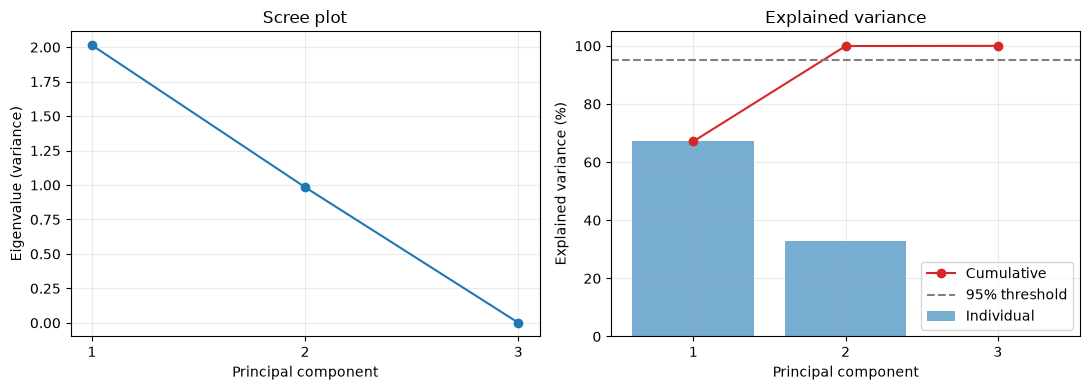

In [9]:
# Scree plot and cumulative explained variance 
pcs = np.arange(1, len(eigvals_sorted) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(pcs, eigvals_sorted, "o-")
axes[0].set_xticks(pcs)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Eigenvalue (variance)")
axes[0].set_title("Scree plot")
axes[0].grid(alpha=0.25)

axes[1].bar(pcs, explained_var_ratio * 100, alpha=0.6, label="Individual")
axes[1].plot(pcs, cum_var * 100, "o-", color="tab:red", label="Cumulative")
axes[1].axhline(95, color="gray", linestyle="--", label="95% threshold")
axes[1].set_xticks(pcs)
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Explained variance (%)")
axes[1].set_title("Explained variance")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

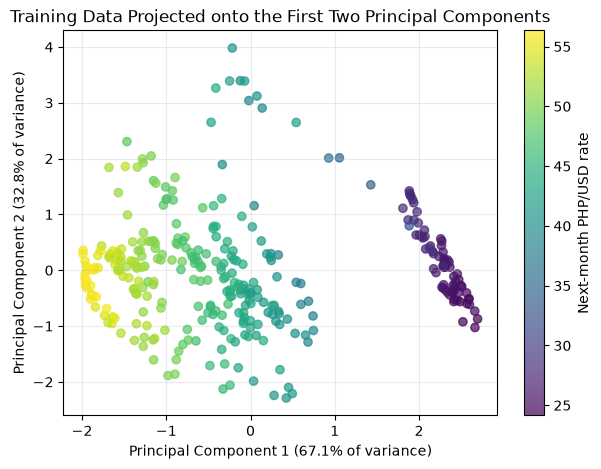

In [10]:
Z_plot = X_train @ V[:, :2]

plt.figure(figsize=(7, 5))
sc = plt.scatter(Z_plot[:, 0], Z_plot[:, 1], c=y_train, cmap="viridis", alpha=0.7)
plt.xlabel(f"Principal Component 1 ({explained_var_ratio[0]*100:.1f}% of variance)")
plt.ylabel(f"Principal Component 2 ({explained_var_ratio[1]*100:.1f}% of variance)")
plt.title("Training Data Projected onto the First Two Principal Components")
plt.colorbar(sc, label="Next-month PHP/USD rate")
plt.grid(alpha=0.25)
plt.show()

### Answer these in your report

**Q25.** Write your diagonalization in the form C = VΛV⁻¹ (or VΛVᵀ). What are the dimensions of V and Λ?

> *Your answer:* We diagonalized the 3 × 3 covariance matrix C of the standardized training features from Part F. Because C is real and symmetric, the spectral theorem lets us choose orthonormal eigenvectors, so V⁻¹ = Vᵀ and the diagonalization is
>
> $$C = V\Lambda V^{T}$$
>
> V is 3 × 3 and its columns are the unit-length eigenvectors, ordered from the largest eigenvalue to the smallest. Λ is 3 × 3 and diagonal, holding the eigenvalues in the same order. Both come from Part F:
>
> $$V = \begin{bmatrix} -0.7024 & -0.0746 & -0.7079 \\ -0.7006 & -0.1031 & 0.7060 \\ -0.1256 & 0.9919 & 0.0201 \end{bmatrix}, \qquad \Lambda = \begin{bmatrix} 2.0141 & 0 & 0 \\ 0 & 0.9841 & 0 \\ 0 & 0 & 0.0017 \end{bmatrix}$$
>
> The columns of V are PC1, PC2, PC3, in that order. PC1 is the "level" direction, with CurrentRate and Trailing3MonthAverage loading about equally. PC2 is almost entirely YearOverYearChange. PC3 is the difference between CurrentRate and Trailing3MonthAverage. The signs of an eigenvector are arbitrary (v and −v are both valid), so the negative signs on PC1 do not matter.

**Q26.** How did you verify, numerically, that your diagonalization is correct?

> *Your answer:* We ran several checks in the notebook, and all of them passed to floating-point round-off:
>
> 1. **Orthonormal V:** `np.allclose(V.T @ V, np.eye(3))` returned `True`, which confirms V⁻¹ = Vᵀ.
> 2. **Reconstruction:** `V @ Lambda @ V.T` was compared with C using `np.allclose`, and the maximum entry-wise difference printed by the notebook is at round-off level (about 10⁻¹⁵ or smaller), the same order as the error in the Part F eigenpair check.
> 3. **Other direction:** VᵀCV returned Λ, and the sum of the three rank-one matrices λᵢvᵢvᵢᵀ returned C.
> 4. **Each eigenpair:** the maximum |Cvᵢ − λᵢvᵢ| over all three pairs is at round-off level, not just for the leading pair as in Part F.
> 5. **Invariants:** trace(C) equals the sum of the eigenvalues (3, because C is a correlation matrix of 3 standardized features), and det(C) equals their product.
> 6. **Scores:** the covariance matrix of the full set of principal-component scores X_train V equals Λ. This shows the new coordinates are uncorrelated and that PCᵢ has variance λᵢ.

**Q27.** How many components did you keep to explain at least 95% of the variance? Why did you choose that threshold?

> *Your answer:* We kept **k = 2** components. PC1 alone explains 67.14% of the variance, which is below 95%. PC1 and PC2 together explain 67.14% + 32.80% = **99.94%**, so the 95% threshold is reached at the second component. PC3 adds only 0.06%. This reduces the training matrix from 342 × 3 to 342 × 2 (and the test matrix from 86 × 3 to 86 × 2), using V_k, the 3 × 2 matrix made of the first two columns of V.
>
> We used 95% because it is the usual convention for PCA: it keeps almost all of the structure in the data and discards what is mostly noise. A lower threshold such as 80% would keep only PC1 and throw away the whole year-over-year signal. A threshold of 100% would keep every component and give no reduction at all. With only p = 3 features the saving is modest, but the reduction does remove the near-duplicate pair identified in Parts E and F. The eigenvalue ratio, which is the condition number from Part E, drops from about 1180 (λ₁/λ₃) to about 2.05 (λ₁/λ₂), so the two kept components are far better conditioned for regression. The 95% cut was set before looking at any regression result and was computed on the training data only.

**Q28.** What is lost — mathematically and practically — when you reduce dimensionality this way? Give a concrete, specific answer for your data.

> *Your answer:*
> **Mathematically.** Projecting onto V_k is a linear map from ℝ³ to ℝ², so it cannot be inverted. Every month is replaced by its closest point in the plane spanned by PC1 and PC2, and the component along PC3 is discarded. The reconstruction X̂ = Z V_kᵀ is only an approximation of X. The average squared reconstruction error per month, summed over the three standardized features, equals the discarded eigenvalue λ₃ ≈ 0.0017, out of a total variance of 3. The notebook confirms this by printing the reconstruction error next to the sum of discarded eigenvalues. Nothing in the data is exactly recoverable once V_k is applied, and the reduced matrix has rank 2 instead of 3.
>
> **Practically, for our data.** The discarded direction PC3 = (−0.7079, 0.7060, 0.0201) is essentially *Trailing3MonthAverage minus CurrentRate*. That difference equals (R₍t−1₎ + R₍t−2₎ − 2Rₜ)/3, so it measures how far the latest month has moved away from the previous two months, which is a very short-term momentum signal. It has a tiny variance because monthly exchange rates move smoothly, so PCA calls it unimportant. That does not mean it is useless for prediction. PCA is unsupervised: it ranks directions by how much the features vary, and it never looks at the target NextMonthRate. A low-variance direction can still carry information about next month's rate. Part H will test this by comparing the full 3-feature model with the 2-component model using RMSE and R² on the test set.
>
> Two other losses are interpretability and scale. PC1 and PC2 are mixtures of the original features, so a coefficient on PC1 can no longer be read as "pesos per peso of CurrentRate", and we would need Vₖ to translate it back to the original features. All components were also fitted on the 1991–2019 training window. If the relationship between the features changes later (for example, a period of sharp depreciation), the directions found in training may no longer be the best ones.

### Save your work for the next notebook

In [11]:
%store V
%store Lambda
%store eigvals_sorted
%store explained_var_ratio
%store cum_var
%store k
%store V_k
%store Z_train
%store Z_test
print("Saved V, Lambda, eigvals_sorted, explained_var_ratio, cum_var, k, V_k, Z_train, Z_test for Part H.")

Stored 'V' (ndarray)
Stored 'Lambda' (ndarray)
Stored 'eigvals_sorted' (ndarray)
Stored 'explained_var_ratio' (ndarray)
Stored 'cum_var' (ndarray)
Stored 'k' (int64)
Stored 'V_k' (ndarray)
Stored 'Z_train' (ndarray)
Stored 'Z_test' (ndarray)
Saved V, Lambda, eigvals_sorted, explained_var_ratio, cum_var, k, V_k, Z_train, Z_test for Part H.
